# Handwritten Character Recognition — CodeAlpha (Task 3)

**Objectif :** reconnaître des chiffres manuscrits (0–9) avec un **réseau de neurones convolutif (CNN)**.

**Dataset :** MNIST — 70 000 images 28×28 en niveaux de gris (60 000 train / 10 000 test).

**Plan du notebook**
1. Chargement et exploration des données
2. Prétraitement
3. Construction du CNN
4. Entraînement
5. Évaluation sur le jeu de test
6. Analyse des erreurs
7. Sauvegarde du modèle
8. Démo interactive (Gradio)

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices('GPU'))

TensorFlow : 2.21.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Chargement et exploration des données

In [ ]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Train :", x_train.shape, y_train.shape)
print("Test  :", x_test.shape, y_test.shape)
print("Valeurs des pixels : min =", x_train.min(), "| max =", x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train : (60000, 28, 28) (60000,)
Test  : (10000, 28, 28) (10000,)
Valeurs des pixels : min = 0 | max = 255


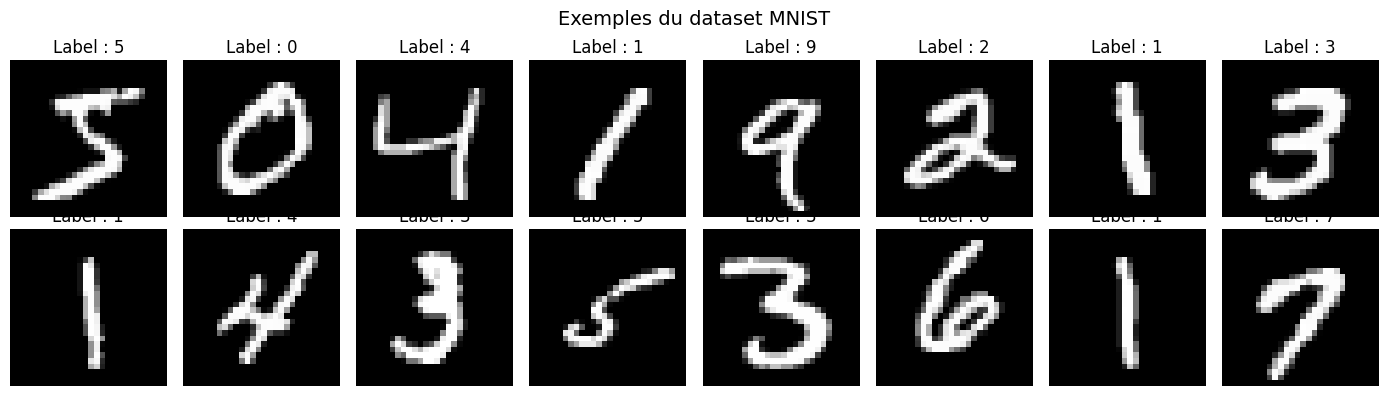

In [ ]:

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label : {y_train[i]}")
    ax.axis("off")
plt.suptitle("Exemples du dataset MNIST", fontsize=14)
plt.tight_layout()
plt.show()

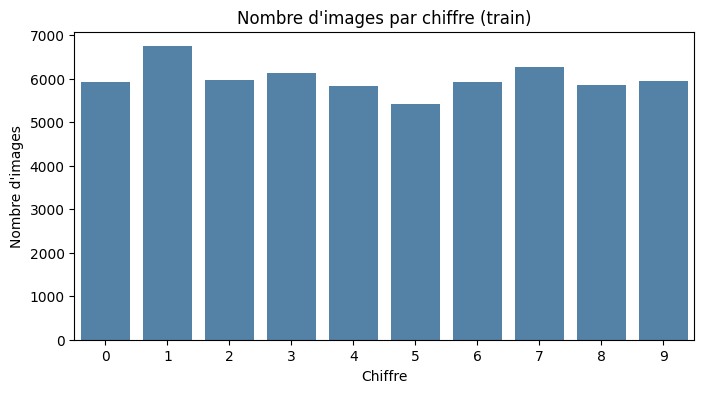

In [ ]:

plt.figure(figsize=(8, 4))
sns.countplot(x=y_train, color="steelblue")
plt.title("Nombre d'images par chiffre (train)")
plt.xlabel("Chiffre"); plt.ylabel("Nombre d'images")
plt.show()


## 2. Prétraitement

In [ ]:

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0


x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Nouvelle forme :", x_train.shape)

Nouvelle forme : (60000, 28, 28, 1)


## 3. Construction du CNN

Architecture :
- **2 blocs convolutifs** (Conv2D → BatchNorm → Conv2D → MaxPooling → Dropout) : ils extraient les traits, courbes et boucles des chiffres.
- **Couche Dense** de 128 neurones + Dropout : elle combine ces motifs.
- **Sortie softmax** à 10 neurones : une probabilité par chiffre.

L'**augmentation de données** (petites rotations, zooms, décalages) n'est active que pendant l'entraînement et rend le modèle plus robuste aux écritures variées.

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name="augmentation")

def build_model():
    model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        data_augmentation,

        # Bloc 1
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),

        # Bloc 2
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),


        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(10, activation="softmax"),
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_model()
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,202 (1.79 MB)

 Trainable params: 468,010 (1.79 MB)

 Non-trainable params: 192 (768.00 B)

## 4. Entraînement

In [ ]:
callbacks = [

    keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),

    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    x_train, y_train,
    validation_split=0.1,
    epochs=15,
    batch_size=128,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 18s 23ms/step - accuracy: 0.4652 - loss: 1.4268 - val_accuracy: 0.7370 - val_loss: 0.9327 - learning_rate: 0.0010
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.7149 - loss: 0.7456 - val_accuracy: 0.9747 - val_loss: 0.0907 - learning_rate: 0.0010
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.8355 - loss: 0.4547 - val_accuracy: 0.9820 - val_loss: 0.0731 - learning_rate: 0.0010
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.8794 - loss: 0.3506 - val_accuracy: 0.9873 - val_loss: 0.0504 - learning_rate: 0.0010
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9233 - loss: 0.2449 - val_accuracy: 0.9842 - val_loss: 0.0571 - learning_rate: 0.0010
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 18ms/step - accuracy: 0.9459 - loss: 0.1898 - val_accuracy: 0.9885 - val_loss: 0.0461 - learning_rate: 0.0010
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - accuracy: 0.9570 - loss: 0

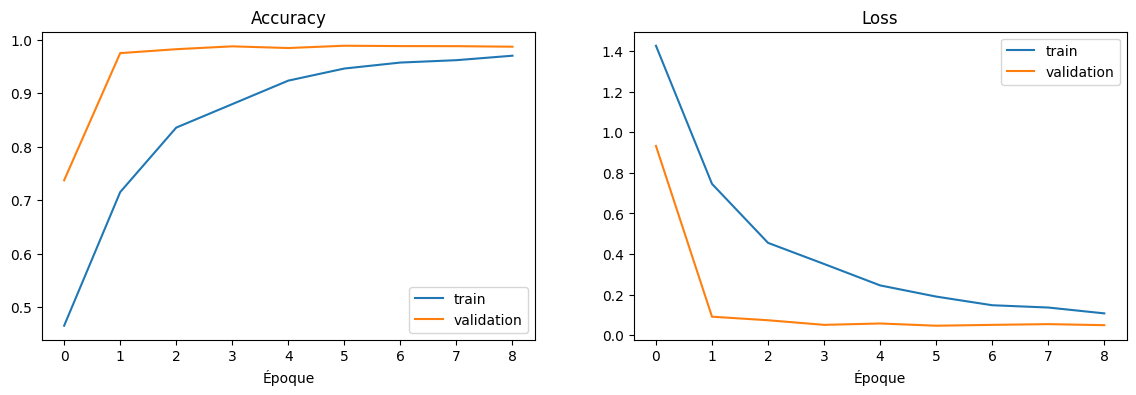

In [ ]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(history.history["accuracy"], label="train")
ax1.plot(history.history["val_accuracy"], label="validation")
ax1.set_title("Accuracy"); ax1.set_xlabel("Époque"); ax1.legend()
ax2.plot(history.history["loss"], label="train")
ax2.plot(history.history["val_loss"], label="validation")
ax2.set_title("Loss"); ax2.set_xlabel("Époque"); ax2.legend()
plt.show()


## 5. Évaluation sur le jeu de test

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"✅ Accuracy sur le test : {test_acc:.4f}  ({test_acc*100:.2f} %)")

y_proba = model.predict(x_test, verbose=0)
y_pred = y_proba.argmax(axis=1)

print("\nRapport de classification :")
print(classification_report(y_test, y_pred, digits=4))

✅ Accuracy sur le test : 0.9879  (98.79 %)

Rapport de classification :
              precision    recall  f1-score   support

           0     0.9959    0.9898    0.9928       980
           1     0.9947    0.9841    0.9894      1135
           2     0.9762    0.9922    0.9841      1032
           3     0.9941    0.9941    0.9941      1010
           4     0.9809    0.9929    0.9868       982
           5     0.9877    0.9910    0.9894       892
           6     0.9803    0.9885    0.9844       958
           7     0.9844    0.9805    0.9825      1028
           8     0.9928    0.9938    0.9933       974
           9     0.9919    0.9732    0.9825      1009

    accuracy                         0.9879     10000
   macro avg     0.9879    0.9880    0.9879     10000
weighted avg     0.9880    0.9879    0.9879     10000



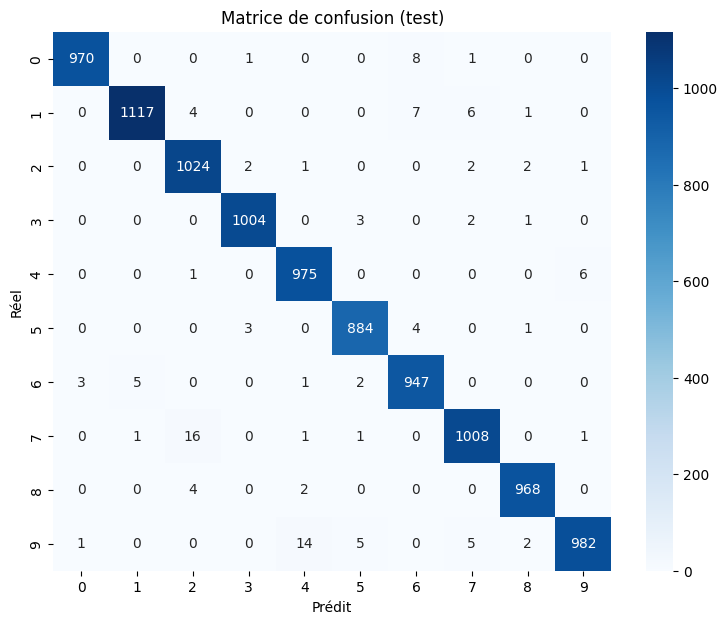

In [ ]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Matrice de confusion (test)")
plt.xlabel("Prédit"); plt.ylabel("Réel")
plt.show()

## 6. Analyse des erreurs

Nombre d'erreurs : 121 / 10000


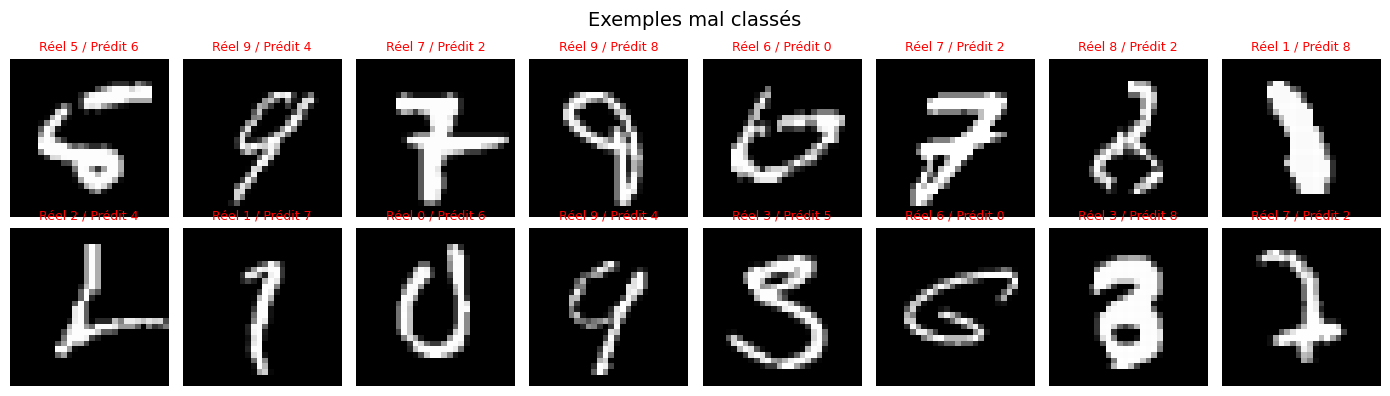

In [ ]:
errors = np.where(y_pred != y_test)[0]
print(f"Nombre d'erreurs : {len(errors)} / {len(y_test)}")

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, idx in zip(axes.flat, errors[:16]):
    ax.imshow(x_test[idx].squeeze(), cmap="gray")
    ax.set_title(f"Réel {y_test[idx]} / Prédit {y_pred[idx]}", fontsize=9, color="red")
    ax.axis("off")
plt.suptitle("Exemples mal classés", fontsize=14)
plt.tight_layout()
plt.show()


## 7. Sauvegarde du modèle

In [ ]:
model.save("mnist_cnn.keras")
print("Modèle sauvegardé : mnist_cnn.keras")



Modèle sauvegardé : mnist_cnn.keras


## 8. Démo interactive

Dessine un chiffre à la souris : le modèle le reconnaît en direct.

Le dessin est prétraité comme les images MNIST : recadrage sur le chiffre, redimensionnement à 20×20, centrage dans une image 28×28 et normalisation.

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
from PIL import Image, ImageFilter
from scipy import ndimage

def preprocess_drawing(img):
    """Convertit le dessin Gradio en image 28x28 façon MNIST (chiffre blanc sur fond noir)."""
    if isinstance(img, dict):                 # Gradio 4+ : {"composite": ..., "layers": ...}
        img = img.get("composite")
    if img is None:
        return None
    img = np.array(img).astype("float32")

    if img.ndim == 3 and img.shape[-1] == 4:
        alpha = img[..., 3:4] / 255.0
        img = img[..., :3] * alpha + 255.0 * (1 - alpha)   # composition sur fond blanc
    gray = img if img.ndim == 2 else img[..., :3].mean(axis=-1)

    ink = 255.0 - gray
    if ink.mean() > 127:                       # sécurité : si le fond était sombre
        ink = 255.0 - ink

    ys, xs = np.where(ink > 50)
    if len(xs) == 0:
        return None
    ink = ink[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

    h, w = ink.shape
    thickness = max(3, int(max(h, w) * 0.08))  # ~8 % de la taille du chiffre
    ink_img = Image.fromarray(ink.clip(0, 255).astype("uint8"))
    ink_img = ink_img.filter(ImageFilter.MaxFilter(thickness | 1))  # taille impaire

    scale = 20.0 / max(h, w)
    new_w, new_h = max(1, int(round(w * scale))), max(1, int(round(h * scale)))
    small = np.array(ink_img.resize((new_w, new_h), Image.LANCZOS)).astype("float32")
    canvas = np.zeros((28, 28), dtype="float32")
    top, left = (28 - new_h) // 2, (28 - new_w) // 2
    canvas[top:top + new_h, left:left + new_w] = small

    cy, cx = ndimage.center_of_mass(canvas)
    canvas = ndimage.shift(canvas, (14 - cy, 14 - cx), mode="constant")
    canvas = np.clip(canvas / max(canvas.max(), 1e-6), 0, 1)
    return canvas[np.newaxis, ..., np.newaxis]

def predict_digit(img):
    x = preprocess_drawing(img)
    if x is None:
        return {}, None
    proba = model.predict(x, verbose=0)[0]
    preview = (x[0, ..., 0] * 255).astype("uint8")   # ce que "voit" le modèle
    return {str(i): float(p) for i, p in enumerate(proba)}, preview

try:
    sketch = gr.Sketchpad(label="Dessine un chiffre (0-9)",
                          brush=gr.Brush(default_size=25, colors=["#000000"], color_mode="fixed"))
except Exception:            # anciennes versions de Gradio
    sketch = gr.Sketchpad(label="Dessine un chiffre (0-9)")

demo = gr.Interface(
    fn=predict_digit,
    inputs=sketch,
    outputs=[gr.Label(num_top_classes=3, label="Prédiction"),
             gr.Image(label="Image 28x28 vue par le modèle", image_mode="L", height=150)],
    title="✍️ Reconnaissance de chiffres manuscrits — CNN",
    description="Projet CodeAlpha, tâche 3. Dessine un chiffre bien gros au centre.",
    live=True,
)
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e10eb08da55f102741.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Conclusion

- Le CNN atteint **98,79 % d'accuracy** sur les 10 000 images de test MNIST (121 erreurs).
- Toutes les classes dépassent 98 % de F1-score ; le chiffre le plus difficile est le **9** (recall de 97,3 %).
- L'augmentation de données, le BatchNorm et le Dropout limitent le sur-apprentissage : l'accuracy de validation (98,85 %) reste supérieure à celle d'entraînement.

**Pistes d'amélioration :**
- Entraîner plus longtemps (patience plus élevée) pour dépasser 99 %.
- Passer à **EMNIST** pour reconnaître aussi les lettres (A–Z).
- Reconnaître des mots entiers avec un **CRNN** (CNN + LSTM + CTC).